# 05 - Contextual-Bandit Reranker (Option A)

## Notebook map (for reviewers)

This notebook builds and stress-tests a contextual-bandit reranker, then compares it to other rerankers. Sections:

1. **Load artifacts** — embeddings + question/node tables.
2. **Cosine baseline** — single-shot Vector RAG; the number to beat.
3. **Train the bandit reranker** — self-critical REINFORCE.
4. **Reranker vs cosine** — cumulative Recall@K, MRR, MAP.
5. **By-hop gain** — ties the result to the multi-hop EDA.
6. **Tree models** — supervised LambdaMART (XGBoost/LightGBM) as stronger baselines.
7. **Performance showdown** — all rerankers + a cross-encoder, ranked by MAP.
8. **Latency** — inference cost per query.
9. **Per-hop showdown** — section 7 broken out by hop count.
10. **Top-N retrieval sweep** — the harder *open-corpus* setting (N = 50/75/100/200).
11. **Save policy.**
12. **Two confirmatory checks** — by-hop on real data + the `s_prf` ablation.
13. **Conclusions.**

All experiments share one loaded `a` and one trained `policy`. Closed-pool sections rerank the fixed ≤20-candidate pool (gold guaranteed present); the Top-N sweep retrieves from the whole corpus (gold *not* guaranteed — that's the point).



**Goal.** Beat the single-shot Vector-RAG (cosine) baseline at reranking each
question's candidate pool, using a *small learned policy* and **no LLM, no
knowledge graph, no agent, no clusters**.

**Method.** Reranking one question's `candidate_node_ids` is framed as a
**contextual bandit** (BanditRank, Pang et al. 2019) - an MDP with episode
length 1 - trained with **self-critical REINFORCE** to directly optimize a
retrieval metric (MAP) instead of a surrogate loss.

**Why it can beat cosine.** The policy scores each candidate from
embedding-only features. The key one is `s_prf` = cosine(candidate, top-1-by-cosine):
a single-step *pseudo-relevance* signal that approximates the bridge structure
your EDA found (later-hop golds sit near the first-hop gold, even when they are
far from the query). With only raw cosine the policy could do no better than the
baseline; `s_prf` is what lets it recover later-hop golds.

**Reading order in the project:** this is the first of two RL retrievers.
Option B (`iterative_query_reformulation`) will make the bridge step *sequential*
instead of a single feature.

References: Pang et al., *BanditRank* (PAKDD 2019); Nogueira & Cho, *Task-Oriented
Query Reformulation with RL* (EMNLP 2017, recall reward); Das et al., *Multi-step
Retriever-Reader Interaction* (ICLR 2019, the self-critical/REINFORCE recipe we
reuse in Option B).

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # tolerate >1 OpenMP runtime (torch + xgboost/lightgbm)
os.environ["OMP_NUM_THREADS"] = "1"           # avoid thread oversubscription on Apple Silicon

import sys; sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import contextual_bandit_reranker as cbr
a = cbr.load_artifacts()

## 1. Load artifacts

`load_artifacts()` reads `doc_emb.npy`, `query_emb.npy`, `query_ids.npy` from
`data/artifacts/` and `nodes.parquet`, `questions.parquet` from `data/interim/`
(paths come from `src/config.py`). It returns the same `a` dict you used in
notebook 03 (`a["questions"]`, `a["node_id_to_idx"]`, ...).

In [2]:
a = cbr.load_artifacts()
print("doc_emb  ", a["doc_emb"].shape)
print("query_emb", a["query_emb"].shape)
print("questions", len(a["questions"]),
      "| splits:", a["questions"]["split"].value_counts().to_dict())
print("n_hops   :", a["questions"]["n_hops"].value_counts().sort_index().to_dict())

doc_emb   (101962, 768)
query_emb (22355, 768)
questions 22355 | splits: {'train': 19938, 'validation': 2417}
n_hops   : {2: 15628, 3: 5147, 4: 1580}


## 2. Baseline: single-shot cosine (Vector RAG)

This is the number we must beat. `evaluate(..., policy=None)` ranks each
candidate pool purely by cosine(query, candidate) and reports cumulative
Recall@K plus MRR / MAP.

In [3]:
KS = list(range(1, 21))
baseline = cbr.evaluate(a, policy=None, split="validation", ks=KS)
baseline_rk = baseline[baseline["K"].apply(lambda x: isinstance(x, int))]
display(baseline_rk[baseline_rk["K"].isin([1, 2, 3, 5, 10, 20])][["K", "recall_cosine"]]
        .reset_index(drop=True))

,K,recall_cosine
0,1,0.324748
1,2,0.495518
2,3,0.585643
3,5,0.703213
4,10,0.861881
5,20,1.000000


## 3. Train the reranker (self-critical REINFORCE)

Knobs live in `TrainConfig`. Defaults are conservative; bump `epochs` if the
greedy reward is still climbing. `reward="map"` gives a dense signal at every
gold position (good for multi-hop); try `"mrr"` if you only care about the first
hit. Set `use_freq=True` to add the corpus-frequency feature from `nodes.parquet`.

In [4]:
cfg = cbr.TrainConfig(
    epochs=15,
    lr=2e-3,
    hidden=32,
    reward="map",      # or "mrr"
    batch_size=32,
    temperature=1.0,
    use_freq=False,
    seed=199806,
)
policy, history = cbr.train_reranker(a, cfg, verbose=True)

epoch  0  greedy_map=0.7094  mean_adv=-0.0453
epoch  1  greedy_map=0.7277  mean_adv=-0.0089
epoch  2  greedy_map=0.7344  mean_adv=-0.0068
epoch  3  greedy_map=0.7398  mean_adv=-0.0066
epoch  4  greedy_map=0.7441  mean_adv=-0.0049
epoch  5  greedy_map=0.7468  mean_adv=-0.0041
epoch  6  greedy_map=0.7477  mean_adv=-0.0032
epoch  7  greedy_map=0.7502  mean_adv=-0.0035
epoch  8  greedy_map=0.7504  mean_adv=-0.0037
epoch  9  greedy_map=0.7493  mean_adv=-0.0028
epoch 10  greedy_map=0.7507  mean_adv=-0.0024
epoch 11  greedy_map=0.7499  mean_adv=-0.0021
epoch 12  greedy_map=0.7500  mean_adv=-0.0020
epoch 13  greedy_map=0.7503  mean_adv=-0.0019
epoch 14  greedy_map=0.7508  mean_adv=-0.0018


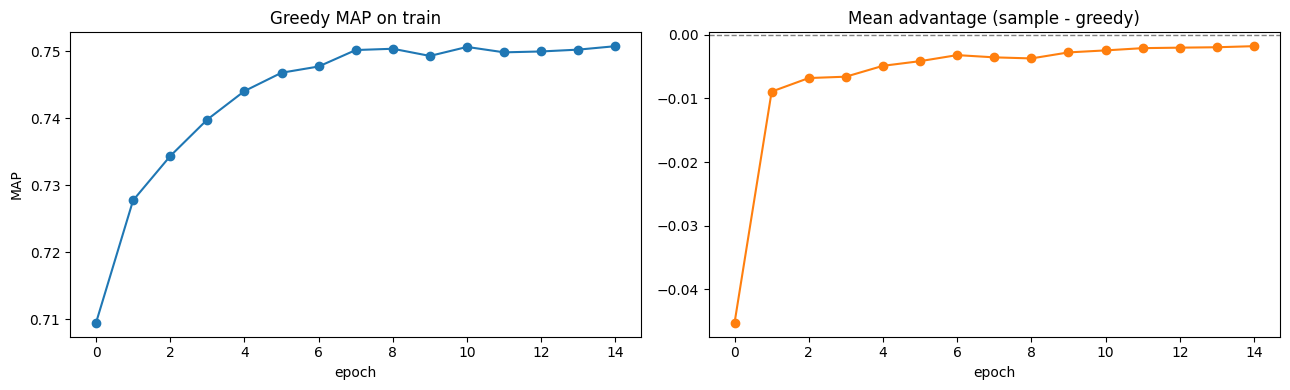

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history["epoch"], history["mean_greedy_reward"], marker="o")
ax[0].set(title=f"Greedy {cfg.reward.upper()} on train", xlabel="epoch", ylabel=cfg.reward.upper())
ax[1].plot(history["epoch"], history["mean_advantage"], marker="o", color="tab:orange")
ax[1].axhline(0, ls="--", c="gray", lw=1)
ax[1].set(title="Mean advantage (sample - greedy)", xlabel="epoch")
plt.tight_layout(); plt.show()

## 4. Evaluate: reranker vs cosine

`delta = recall_reranker - recall_cosine`. We expect the gain to be small at
K=1 (hop-1 golds are already easy for cosine) and larger at K=2..5 (where the
later-hop golds were being missed).

In [6]:
res = cbr.evaluate(a, policy, split="validation", ks=KS)
res_rk = res[res["K"].apply(lambda x: isinstance(x, int))].copy()
display(res_rk[res_rk["K"].isin([1, 2, 3, 5, 10, 20])]
        [["K", "recall_cosine", "recall_reranker", "delta"]].reset_index(drop=True))

for label in ["MRR", "MAP"]:
    r = res[res["K"] == label].iloc[0]
    print(f"{label}: cosine={r['recall_cosine']:.4f}  "
          f"reranker={r['recall_reranker']:.4f}  delta={r['delta']:+.4f}")

,K,recall_cosine,recall_reranker,delta
0,1,0.324748,0.339677,0.014929
1,2,0.495518,0.528444,0.032926
2,3,0.585643,0.639015,0.053372
3,5,0.703213,0.765101,0.061888
4,10,0.861881,0.907013,0.045132
5,20,1.000000,1.000000,0.000000


MRR: cosine=0.8744  reranker=0.9032  delta=+0.0289
MAP: cosine=0.6705  reranker=0.7211  delta=+0.0506


In [7]:
print(res_rk[res_rk["K"].isin([1, 2, 3, 5, 10, 20])]
        [["K", "recall_cosine", "recall_reranker", "delta"]].reset_index(drop=True))

    K  recall_cosine  recall_reranker     delta
0   1       0.324748         0.339677  0.014929
1   2       0.495518         0.528444  0.032926
2   3       0.585643         0.639015  0.053372
3   5       0.703213         0.765101  0.061888
4  10       0.861881         0.907013  0.045132
5  20       1.000000         1.000000  0.000000


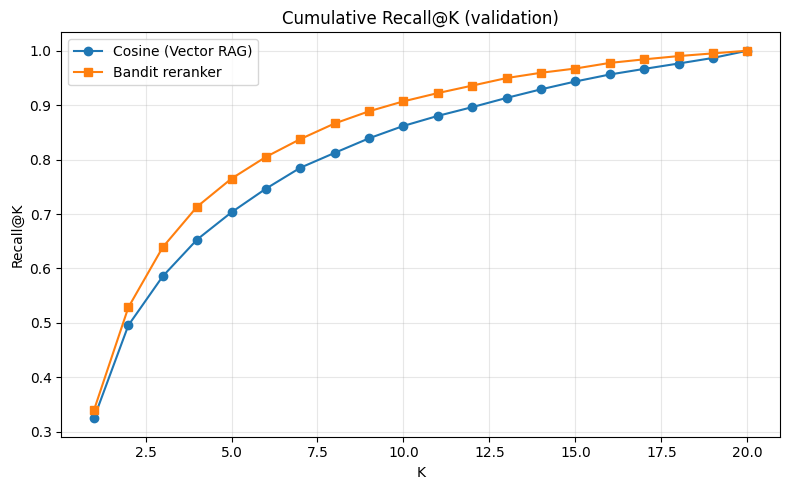

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(res_rk["K"], res_rk["recall_cosine"], marker="o", label="Cosine (Vector RAG)")
plt.plot(res_rk["K"], res_rk["recall_reranker"], marker="s", label="Bandit reranker")
plt.xlabel("K"); plt.ylabel("Recall@K"); plt.title("Cumulative Recall@K (validation)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. The multi-hop story: gain by hop count

This is the plot that ties the result to your EDA. If the reranker is doing what
we think (recovering bridge-linked later-hop golds), the improvement should
**grow with the number of hops**.

delta                     recall_cosine                      \
K            3         5         10            3         5         10   
group                                                                   
2      0.055112  0.063498  0.044329      0.667332  0.766374  0.895767   
3      0.050000  0.058333  0.033333      0.553947  0.691667  0.867982   
4      0.054321  0.063580  0.069753      0.392593  0.529630  0.745679   

      recall_reranker                      
K                  3         5         10  
group                                      
2            0.722444  0.829872  0.940096  
3            0.603947  0.750000  0.901316  
4            0.446914  0.593210  0.815432

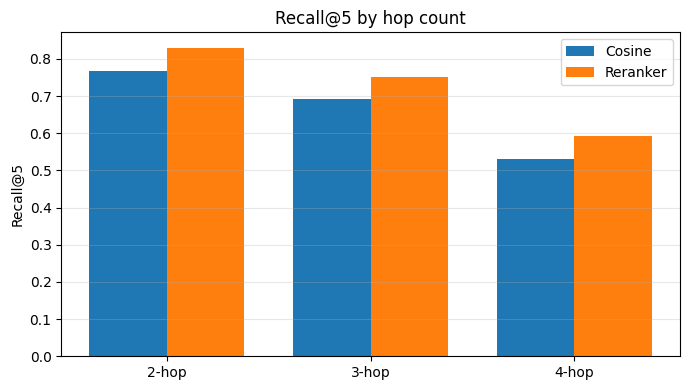

In [9]:
byhop = cbr.evaluate(a, policy, split="validation", ks=[3, 5, 10], by_hop=True)
byhop_rk = byhop[byhop["K"].apply(lambda x: isinstance(x, int))]
display(byhop_rk.pivot_table(index="group", columns="K",
        values=["recall_cosine", "recall_reranker", "delta"]))

sub = byhop_rk[byhop_rk["K"] == 5]
plt.figure(figsize=(7, 4))
x = np.arange(len(sub)); w = 0.38
plt.bar(x - w/2, sub["recall_cosine"], w, label="Cosine")
plt.bar(x + w/2, sub["recall_reranker"], w, label="Reranker")
plt.xticks(x, [f"{g}-hop" for g in sub["group"]])
plt.ylabel("Recall@5"); plt.title("Recall@5 by hop count"); plt.legend()
plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

## 6. Tree models (supervised LambdaMART baselines)

XGBoost and LightGBM rankers trained on the **same geometric features** as the bandit (`s_query`, `s_prf`, `s_centroid`, `s_maxother`, `rank_q`). These are the natural stronger baseline: classic supervised learning-to-rank with explicit gold labels. The question they answer is whether our direct-metric RL actually *needs* RL, or whether ordinary supervised LTR does as well. (Spoiler from the results: they land within ~1 point of each other.)

In [11]:
# 1. Train XGBoost
print("Training XGBoost...")
xgb_model = cbr.train_tree_ranker(a, method="xgboost")

# 2. Train LightGBM
print("Training LightGBM...")
lgbm_model = cbr.train_tree_ranker(a, method="lightgbm")

print("Tree models trained successfully.")

Training XGBoost...
Training LightGBM...
Tree models trained successfully.


## 7. Performance showdown

All rerankers on the same validation pools, ranked by MAP: cosine baseline, the RL bandit, the two trees, and a **cross-encoder** (`BAAI/bge-reranker-base`) — a heavyweight model that reads raw query+document text. Key thing to look for: the cross-encoder *underperforms* the lightweight embedding rerankers despite being far more expensive, because it scores query↔document relevance — the exact axis on which later-hop golds fail. Bigger relevance model ≠ better multi-hop retrieval.

In [12]:
# 1. Baseline + RL scores from the existing evaluate()
base_res = cbr.evaluate(a, policy, split="validation", ks=[1, 3, 5, 10])
records = []
for _, row in base_res.iterrows():
    k = row["K"]
    records.append({"Model": "Cosine Baseline",      "K": k, "Score": row["recall_cosine"]})
    records.append({"Model": "RL Contextual Bandit",  "K": k, "Score": row["recall_reranker"]})

# 2. Tree scores
xgb_res  = cbr.evaluate_tree_ranker(a, xgb_model,  split="validation", ks=[1, 3, 5, 10])
lgbm_res = cbr.evaluate_tree_ranker(a, lgbm_model, split="validation", ks=[1, 3, 5, 10])

# 3. Cross-encoder scores (first run downloads ~400 MB; slow on MPS — not a hang)
print("Running Cross-Encoder evaluation (this will take a moment)...")
ce_res = cbr.evaluate_cross_encoder(a, split="validation", ks=[1, 3, 5, 10])

# 4. Combine + pivot
all_res = pd.concat([pd.DataFrame(records), xgb_res, lgbm_res, ce_res])
comparison_df = all_res.pivot(index="Model", columns="K", values="Score")
comparison_df = comparison_df[[1, 3, 5, 10, "MRR", "MAP"]]
print("\n--- RERANKER PERFORMANCE SHOWDOWN ---")
display(comparison_df.round(4).sort_values(by="MAP", ascending=False))

/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati

Running Cross-Encoder evaluation (this will take a moment)...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 7171.95it/s]



--- RERANKER PERFORMANCE SHOWDOWN ---


K,1,3,5,10,MRR,MAP
Model,,,,,,
XGBRanker,0.3429,0.6448,0.7726,0.9114,0.9090,0.7289
LGBMRanker,0.3436,0.6457,0.7724,0.9105,0.9105,0.7284
RL Contextual Bandit,0.3397,0.6390,0.7651,0.9070,0.9032,0.7211
CrossEncoder,0.3371,0.6167,0.7122,0.8405,0.8982,0.6894
Cosine Baseline,0.3247,0.5856,0.7032,0.8619,0.8744,0.6705


In [15]:
print(comparison_df.round(4).sort_values(by="MAP", ascending=False))

K                          1       3       5      10     MRR     MAP
Model                                                               
XGBRanker             0.3429  0.6448  0.7726  0.9114  0.9090  0.7289
LGBMRanker            0.3436  0.6457  0.7724  0.9105  0.9105  0.7284
RL Contextual Bandit  0.3397  0.6390  0.7651  0.9070  0.9032  0.7211
CrossEncoder          0.3371  0.6167  0.7122  0.8405  0.8982  0.6894
Cosine Baseline       0.3247  0.5856  0.7032  0.8619  0.8744  0.6705


## 8. Inference latency (per query, ≤20 candidates)

Cost side of the cost/quality story. The learned rerankers (RL + trees) run in well under a millisecond; the cross-encoder is ~2–3 orders of magnitude slower because it runs a transformer forward pass over every query–document pair. This is the empirical backing for "add a cheap learned policy, not an expensive model."

In [13]:
import time, torch

test_pools = list(cbr.iter_query_pools(a, split="validation"))[:100]
q_df = a["questions"].set_index("question_id")
n_df = a["nodes"].set_index("node_id")
timers = {}

# 1. RL agent (features + PyTorch MLP)
start = time.time()
for pool in test_pools:
    feats = cbr.build_features(pool.query_vec, pool.cand_vecs)
    with torch.no_grad():
        _ = cbr.greedy_ranking(policy(torch.from_numpy(feats)))
timers["RL Contextual Bandit"] = (time.time() - start) / len(test_pools)

# 2. XGBoost (features + C++ trees)
start = time.time()
for pool in test_pools:
    feats = cbr.build_features(pool.query_vec, pool.cand_vecs)
    _ = xgb_model.predict(feats)
timers["XGBRanker"] = (time.time() - start) / len(test_pools)

# 3. LightGBM
start = time.time()
for pool in test_pools:
    feats = cbr.build_features(pool.query_vec, pool.cand_vecs)
    _ = lgbm_model.predict(feats)
timers["LGBMRanker"] = (time.time() - start) / len(test_pools)

# 4. Cross-encoder (tokenization + transformer forward pass)
from sentence_transformers import CrossEncoder
device = "mps" if torch.backends.mps.is_available() else "cpu"
ce = CrossEncoder("BAAI/bge-reranker-base", device=device, max_length=256)
start = time.time()
for pool in test_pools:
    query_text = str(q_df.loc[pool.question_id, "query_text"])          # was "question"
    cand_texts = [(str(n_df.loc[int(n), "title"]) + ". " + str(n_df.loc[int(n), "text"])).strip()
                  for n in pool.cand_node_ids]
    _ = ce.predict([(query_text, doc) for doc in cand_texts])
timers["CrossEncoder"] = (time.time() - start) / len(test_pools)

print("--- INFERENCE LATENCY (Per Query, Max 20 Candidates) ---")
for model, sec in timers.items():
    print(f"{model:<25}: {sec * 1000:>6.2f} ms")

/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati

--- INFERENCE LATENCY (Per Query, Max 20 Candidates) ---
RL Contextual Bandit     :   0.12 ms
XGBRanker                :   0.20 ms
LGBMRanker               :   0.34 ms
CrossEncoder             : 322.19 ms


## 9. Per-hop showdown

Section 5 broken out for every model: Recall@`K_HOP` split by question hop count (2 / 3 / 4). Confirms the gain is largest exactly where single-shot cosine is weakest (the hardest, highest-hop queries). Note `K_HOP` at the top of the cell — set it consistently with whatever K you report elsewhere.

In [17]:
# --- Per-hop comparison: Recall@K split by n_hops (2 / 3 / 4) ---
K_HOP = 5            # change to taste (1, 3, 5, 10...)
INCLUDE_CE = True    # set False to skip the slow cross-encoder

# Load the cross-encoder ONCE, outside the loop
ce = None
if INCLUDE_CE:
    from sentence_transformers import CrossEncoder
    dev = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
    ce = CrossEncoder("BAAI/bge-reranker-base", device=dev, max_length=256)

q_df = a["questions"].set_index("question_id")
n_df = a["nodes"].set_index("node_id")

rows = []
for pool in cbr.iter_query_pools(a, split="validation"):
    feats_np = cbr.build_features(pool.query_vec, pool.cand_vecs)
    feats_t = torch.from_numpy(feats_np)

    rankings = {}
    rankings["Cosine Baseline"] = np.argsort(-feats_np[:, 0])   # col 0 = s_query (monotone in cosine)
    with torch.no_grad():
        rankings["RL Contextual Bandit"] = cbr.greedy_ranking(policy(feats_t))
    rankings["XGBRanker"]  = np.argsort(-xgb_model.predict(feats_np))
    rankings["LGBMRanker"] = np.argsort(-lgbm_model.predict(feats_np))
    if ce is not None:
        qt = str(q_df.loc[pool.question_id, "query_text"])
        cts = [(str(n_df.loc[int(n), "title"]) + ". " + str(n_df.loc[int(n), "text"])).strip()
               for n in pool.cand_node_ids]
        sc = ce.predict([(qt, d) for d in cts], show_progress_bar=False)
        rankings["CrossEncoder"] = np.argsort(-np.asarray(sc))

    for model, rank in rankings.items():
        rows.append({"Model": model, "n_hops": pool.n_hops,
                     "Recall": cbr.recall_at_k(rank, pool.gold_local, K_HOP)})

df = pd.DataFrame(rows)
per_hop = df.pivot_table(index="Model", columns="n_hops", values="Recall", aggfunc="mean")
per_hop["all"] = df.groupby("Model")["Recall"].mean()
per_hop.columns = [f"{c}-hop" if isinstance(c, (int, np.integer)) else c for c in per_hop.columns]

print(f"--- Recall@{K_HOP} BY HOP COUNT ---")
display(per_hop.round(4).sort_values(by="all", ascending=False))

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 7206.58it/s]
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-ra

--- Recall@5 BY HOP COUNT ---


,2-hop,3-hop,4-hop,all
Model,,,,
XGBRanker,0.8395,0.7478,0.6123,0.7726
LGBMRanker,0.8407,0.7430,0.6167,0.7724
RL Contextual Bandit,0.8299,0.7500,0.5932,0.7651
CrossEncoder,0.7923,0.6890,0.5080,0.7122
Cosine Baseline,0.7664,0.6917,0.5296,0.7032


In [18]:
print(per_hop.round(4).sort_values(by="all", ascending=False))

                       2-hop   3-hop   4-hop     all
Model                                               
XGBRanker             0.8395  0.7478  0.6123  0.7726
LGBMRanker            0.8407  0.7430  0.6167  0.7724
RL Contextual Bandit  0.8299  0.7500  0.5932  0.7651
CrossEncoder          0.7923  0.6890  0.5080  0.7122
Cosine Baseline       0.7664  0.6917  0.5296  0.7032


Some quick updates from my side:

I built a reranking step for our Vector RAG, using only the embeddings, no clusters. We'd originally wanted to avoid building a knowledge graph, as it is expensive to build it, so we built the clusters based on embeddings to set up a sequential RL environment where the agent would learn to traverse and retrieve from clusters. But we couldn't pin down a concrete way to actually implement that, so I started with the easier problem first.

The problem the RL agent solves here is reranking. In a Vector RAG you normally grab the top-k docs by cosine similarity and then rerank them, usually with a cross-encoder. But on our multi-hop dataset the cross-encoder does poorly, as purely semantic reranking isn't enough to surface the later-hop documents.

So instead I trained a contextual-bandit RL agent to do the reranking: it reorders the retrieved candidates to push the relevant ones toward the top, and gets rewarded when the gold documents end up ranked high. I also trained XGBoost and LightGBM rankers as supervised benchmarks.

The analysis is on recall and latency. The RL agent was close to the supervised rankers but slightly worse — and all three clearly beat the cross-encoder (and are much faster).

One more finding: even with the top-200 cosine results we still miss 20%+ of the gold docs, and widening the window doesn't help the rerankers much — the returns diminish fast. So reranking alone isn't enough. That's basically the motivation to make the RL work sequentially (for example retrieve - reformulate - retrieve again), which is the setting where the RL approach could actually beat the supervised ones.

tbh I haven't reviewed exactly how the contextual bandit works under the hood yet. I'll try to go through it before our meeting.

## 10. Open-corpus Top-N retrieval sweep

**Different setup from everything above.** Sections 1–9 rerank the fixed ≤20-candidate pool where the gold is *guaranteed present* (recall ceiling = 1.0). Here we instead retrieve the top-N documents from the **entire corpus** by cosine (N = 50/75/100/200) and rerank those — the realistic open-corpus task, where gold is *not* guaranteed to be retrieved.

Each model is retrained on the top-N train pools at every N. Recall is divided by the *true* gold count, so gold the first stage missed counts as a miss. The reported **`ceiling`** = first-stage recall@N = the most gold any reranker could possibly surface at that N.

How to read it: watch the gap between each model's line and the dashed ceiling. As N grows the ceiling rises (more gold captured) but the gap *widens* — the late-arriving gold is the semantically-distant gold that embedding rerankers can't surface either. Even at N=200 a large fraction of gold is unreachable by cosine. **This is the wall that reranking cannot break, and the motivation for iterative retrieval (Option B).**

In [19]:
from src import topk_retrieval_experiment as tk

sweep = tk.run_topn_sweep(
    a,
    ns=(50, 75, 100, 200),
    ks=(1, 5, 10, 20),
    models=("cosine", "rl", "xgboost", "lightgbm"),
    rl_epochs=10,        # bump if the RL is still climbing
    rl_top_m=30,         # truncate Plackett-Luce to top-30 (keeps N=200 fast)
    n_estimators=100,
    verbose=True,
)
display(sweep.round(4))


=== N = 50 ===
  first-stage recall ceiling (val): 0.6558
  training RL...
  training XGBoost...
  training LightGBM...


/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati


=== N = 75 ===
  first-stage recall ceiling (val): 0.6904
  training RL...
  training XGBoost...
  training LightGBM...


/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati


=== N = 100 ===
  first-stage recall ceiling (val): 0.7135
  training RL...
  training XGBoost...
  training LightGBM...


/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati


=== N = 200 ===
  first-stage recall ceiling (val): 0.7636
  training RL...
  training XGBoost...
  training LightGBM...


/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati

,N,Model,ceiling,R@1,R@5,R@10,R@20,MRR,MAP
0,50,Cosine Baseline,0.6558,0.2576,0.4544,0.5145,0.5743,0.7169,0.4022
1,50,RL Contextual Bandit,0.6558,0.2092,0.3756,0.4719,0.5543,0.6036,0.3334
2,50,XGBRanker,0.6558,0.2800,0.4716,0.5297,0.5897,0.7672,0.4270
3,50,LGBMRanker,0.6558,0.2814,0.4794,0.5350,0.5961,0.7715,0.4318
4,75,Cosine Baseline,0.6904,0.2576,0.4546,0.5145,0.5743,0.7171,0.4035
5,75,RL Contextual Bandit,0.6904,0.2868,0.4731,0.5320,0.5870,0.7809,0.4334
6,75,XGBRanker,0.6904,0.2807,0.4759,0.5358,0.5968,0.7703,0.4332
7,75,LGBMRanker,0.6904,0.2840,0.4797,0.5406,0.5996,0.7770,0.4360
8,100,Cosine Baseline,0.7135,0.2576,0.4546,0.5145,0.5743,0.7172,0.4041
9,100,RL Contextual Bandit,0.7135,0.2873,0.4757,0.5306,0.5850,0.7826,0.4338


In [22]:
print(sweep.round(4))

      N                 Model  ceiling     R@1     R@5    R@10    R@20  \
0    50       Cosine Baseline   0.6558  0.2576  0.4544  0.5145  0.5743   
1    50  RL Contextual Bandit   0.6558  0.2092  0.3756  0.4719  0.5543   
2    50             XGBRanker   0.6558  0.2800  0.4716  0.5297  0.5897   
3    50            LGBMRanker   0.6558  0.2814  0.4794  0.5350  0.5961   
4    75       Cosine Baseline   0.6904  0.2576  0.4546  0.5145  0.5743   
5    75  RL Contextual Bandit   0.6904  0.2868  0.4731  0.5320  0.5870   
6    75             XGBRanker   0.6904  0.2807  0.4759  0.5358  0.5968   
7    75            LGBMRanker   0.6904  0.2840  0.4797  0.5406  0.5996   
8   100       Cosine Baseline   0.7135  0.2576  0.4546  0.5145  0.5743   
9   100  RL Contextual Bandit   0.7135  0.2873  0.4757  0.5306  0.5850   
10  100             XGBRanker   0.7135  0.2797  0.4767  0.5391  0.5991   
11  100            LGBMRanker   0.7135  0.2836  0.4825  0.5414  0.6039   
12  200       Cosine Baseline   0.7636

In [23]:
for metric in ["R@5", "R@10", "R@20", "MAP", "MRR"]:
    print(f"\n=== {metric} by N ===")
    print(tk.pivot_metric(sweep, metric).round(4))


=== R@5 by N ===
N                             50      75      100     200
Model                                                    
Cosine Baseline            0.4544  0.4546  0.4546  0.4546
LGBMRanker                 0.4794  0.4797  0.4825  0.4745
RL Contextual Bandit       0.3756  0.4731  0.4757  0.4765
XGBRanker                  0.4716  0.4759  0.4767  0.4758
-- first-stage ceiling --  0.6558  0.6904  0.7135  0.7636

=== R@10 by N ===
N                             50      75      100     200
Model                                                    
Cosine Baseline            0.5145  0.5145  0.5145  0.5145
LGBMRanker                 0.5350  0.5406  0.5414  0.5388
RL Contextual Bandit       0.4719  0.5320  0.5306  0.5375
XGBRanker                  0.5297  0.5358  0.5391  0.5433
-- first-stage ceiling --  0.6558  0.6904  0.7135  0.7636

=== R@20 by N ===
N                             50      75      100     200
Model                                                    
Cosine Baseline 

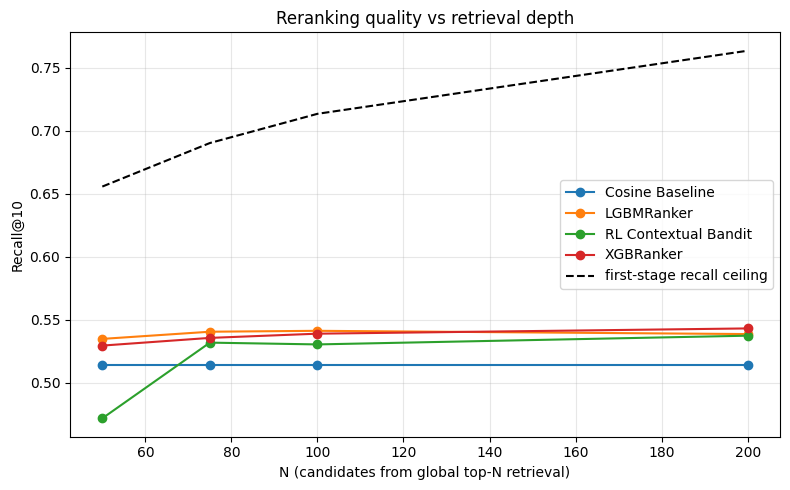

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for model, g in sweep.groupby("Model"):
    ax.plot(g["N"], g["R@10"], marker="o", label=model)
ceil = sweep.drop_duplicates("N")
ax.plot(ceil["N"], ceil["ceiling"], "k--", lw=1.5, label="first-stage recall ceiling")
ax.set_xlabel("N (candidates from global top-N retrieval)")
ax.set_ylabel("Recall@10")
ax.set_title("Reranking quality vs retrieval depth")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 11. Save the trained policy

In [16]:
from src import config
out = config.ARTIFACTS_DIR / "reranker_policy.pt"
cbr.save_policy(policy, out, cfg, n_feat=len(cbr.feature_names(cfg.use_freq)))
print("saved ->", out)

saved -> /Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/data/artifacts/reranker_policy.pt


## 12. Two confirmatory checks

Two analyses that turn "we beat the baseline" into "we beat it and we know why":

1. **By-hop on real data** (next cell) — Recall@K split by hop count for all models, confirming the lift concentrates on the hardest multi-hop queries.
2. **Feature ablation** (cell below that) — the decisive one. See its own note.

/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati

=== Recall@10 by hop count ===


/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRanker was fitted with feature names
  warnings.warn(
/Users/macbookpro/Documents/DSDM/Term_3/Reinforcement_Learning/final_project/rl-graph-rag-retrieval/.venv/lib/python3.13/site-packages/sklearn/utils/validati

Model,Cosine,RL,XGB,LGBM,n_q
hop,,,,,
2,0.8958,0.9401,0.9469,0.9453,1252
3,0.8680,0.9013,0.9004,0.9000,760
4,0.7457,0.8154,0.8222,0.8228,405



=== Delta over cosine (Recall@10) ===


Model,RL,XGB,LGBM
hop,,,
2,0.0443,0.0511,0.0495
3,0.0333,0.0325,0.0320
4,0.0698,0.0765,0.0772


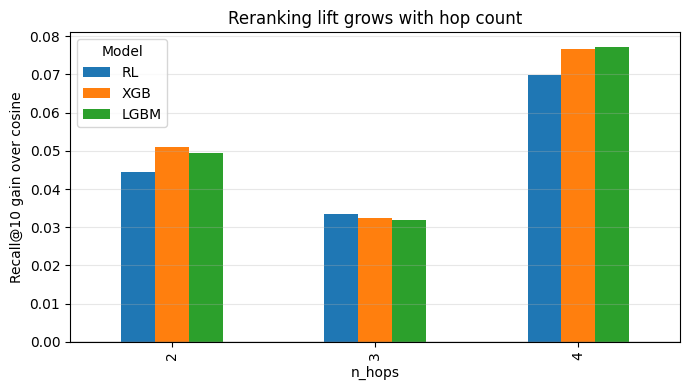

In [26]:
import torch, numpy as np, pandas as pd

K_HOP = 10
rows = []
for pool in cbr.iter_query_pools(a, split="validation"):
    feats_np = cbr.build_features(pool.query_vec, pool.cand_vecs)
    feats_t = torch.from_numpy(feats_np)
    rk = {"Cosine": np.argsort(-feats_np[:, 0])}
    with torch.no_grad():
        rk["RL"] = cbr.greedy_ranking(policy(feats_t))
    rk["XGB"]  = np.argsort(-xgb_model.predict(feats_np))
    rk["LGBM"] = np.argsort(-lgbm_model.predict(feats_np))
    for m, r in rk.items():
        rows.append({"hop": pool.n_hops, "Model": m,
                     f"R@{K_HOP}": cbr.recall_at_k(r, pool.gold_local, K_HOP)})

df = pd.DataFrame(rows)
counts = df[df.Model == "Cosine"].groupby("hop").size()
tab = df.groupby(["hop", "Model"])[f"R@{K_HOP}"].mean().unstack()[["Cosine", "RL", "XGB", "LGBM"]]
tab["n_q"] = counts
print(f"=== Recall@{K_HOP} by hop count ===")
display(tab.round(4))

print(f"\n=== Delta over cosine (Recall@{K_HOP}) ===")
display(tab[["RL", "XGB", "LGBM"]].sub(tab["Cosine"], axis=0).round(4))

# bar chart of the delta
import matplotlib.pyplot as plt
delta = tab[["RL", "XGB", "LGBM"]].sub(tab["Cosine"], axis=0)
ax = delta.plot(kind="bar", figsize=(7, 4))
ax.set_xlabel("n_hops"); ax.set_ylabel(f"Recall@{K_HOP} gain over cosine")
ax.set_title("Reranking lift grows with hop count"); ax.axhline(0, c="gray", lw=1)
ax.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

In [31]:
print(tab.round(4))
print(tab[["RL", "XGB", "LGBM"]].sub(tab["Cosine"], axis=0).round(4))

Model  Cosine      RL     XGB    LGBM   n_q
hop                                        
2      0.8958  0.9401  0.9469  0.9453  1252
3      0.8680  0.9013  0.9004  0.9000   760
4      0.7457  0.8154  0.8222  0.8228   405
Model      RL     XGB    LGBM
hop                          
2      0.0443  0.0511  0.0495
3      0.0333  0.0325  0.0320
4      0.0698  0.0765  0.0772


### Feature ablation: where does the gain come from?

An ablation *ladder* on the bandit's features:

- `full` — all features.
- `no_s_prf` — drop only the bridge / pseudo-relevance feature.
- `query_only` — drop all pseudo-relevance features, leaving only query↔document signal.

The result to look for: dropping `s_prf` roughly halves the gain, and `query_only` collapses **exactly to cosine** (gain ≈ 0). That proves the entire reranking benefit comes from the inter-document/bridge signal — the model learns nothing useful from query↔document relevance beyond what cosine already encodes. (Note: this cell rebinds `cfg`; the policy saved in section 11 used the original training `cfg`.)

In [28]:
ABLATIONS = {
    "full":        None,                               # all features
    "no_s_prf":    {"s_prf"},                           # drop just the bridge feature
    "query_only":  {"s_prf", "s_centroid", "s_maxother"},  # no pseudo-relevance at all
}

cfg = cbr.TrainConfig(epochs=15, lr=2e-3, seed=199806)   # same config across variants

rows = []
for name, drop in ABLATIONS.items():
    pol, _ = cbr.train_reranker(a, cfg, verbose=False, drop_features=drop)
    res = cbr.evaluate(a, pol, split="validation", ks=[5, 10], drop_features=drop)
    cos_map = res[res.K == "MAP"].iloc[0]["recall_cosine"]
    rl_map  = res[res.K == "MAP"].iloc[0]["recall_reranker"]
    rl_r5   = res[res.K == 5].iloc[0]["recall_reranker"]

    xgb_a  = cbr.train_tree_ranker(a, "xgboost",  drop_features=drop)
    xgb_r  = cbr.evaluate_tree_ranker(a, xgb_a, ks=[5], drop_features=drop)
    xgb_map = xgb_r[xgb_r.K == "MAP"].iloc[0]["Score"]

    rows.append({"features": name, "cosine_MAP": cos_map,
                 "RL_MAP": rl_map, "RL_R@5": rl_r5, "XGB_MAP": xgb_map,
                 "RL_gain_over_cosine": rl_map - cos_map})

abl = pd.DataFrame(rows).set_index("features")
print("=== s_prf ablation ladder (validation) ===")
display(abl.round(4))

=== s_prf ablation ladder (validation) ===


,cosine_MAP,RL_MAP,RL_R@5,XGB_MAP,RL_gain_over_cosine
features,,,,,
full,0.6705,0.7211,0.7651,0.7289,0.0506
no_s_prf,0.6705,0.6969,0.7246,0.6980,0.0264
query_only,0.6705,0.6705,0.7032,0.6699,0.0000


In [29]:
print(abl.round(4))

            cosine_MAP  RL_MAP  RL_R@5  XGB_MAP  RL_gain_over_cosine
features                                                            
full            0.6705  0.7211  0.7651   0.7289               0.0506
no_s_prf        0.6705  0.6969  0.7246   0.6980               0.0264
query_only      0.6705  0.6705  0.7032   0.6699               0.0000


## 13. Conclusions

- A small learned reranker beats single-shot cosine on the closed pool (≈ +0.05 MAP), with the gain concentrated on higher-hop queries.
- The gain is **entirely** attributable to the bridge/pseudo-relevance signal (ablation: query-only ranker = cosine exactly). A cross-encoder, the strongest query↔document relevance model here, *loses* to sub-millisecond embedding rerankers — same conclusion from the opposite direction.
- The RL bandit ≈ supervised LambdaMART (within ~1 pt). For this single-step, fully-labelled task, RL matches but does not beat supervised LTR; its edge is inference speed and that it's the stepping stone to the sequential setting.
- Open-corpus sweep: reranking cannot exceed first-stage recall, and a large share of gold is unreachable by cosine at any depth. → motivates **Option B (iterative query reformulation)**.

In [15]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from src import contextual_bandit_reranker as cbr

# ==========================================================================
# 1. Top-100 Precomputation & Monkey Patch
# ==========================================================================
def precompute_topk_cosines(a: dict, k: int = 100, batch_size: int = 256) -> dict:
    """Finds the top-K documents across the entire corpus for each query."""
    doc_emb   = a["doc_emb"]
    query_emb = a["query_emb"]
    n_queries = len(query_emb)

    topk_indices = np.empty((n_queries, k), dtype=np.int32)
    topk_scores  = np.empty((n_queries, k), dtype=np.float32)

    for start in range(0, n_queries, batch_size):
        end   = min(start + batch_size, n_queries)
        batch = query_emb[start:end]
        cos   = doc_emb @ batch.T
        idx   = np.argpartition(-cos, k, axis=0)[:k]

        for j in range(end - start):
            top_idx = idx[:, j]
            sorted_top = top_idx[np.argsort(-cos[top_idx, j])]
            topk_indices[start + j] = sorted_top
            topk_scores[start + j]  = cos[sorted_top, j]

    a["topk_indices"] = topk_indices
    a["topk_scores"]  = topk_scores
    a["topk_k"]       = k
    return a

def custom_iter_query_pools(a: dict, split: str | None = None):
    """Overwrites standard cbr behavior to load the 100 docs instead of 20.

    NOTE: this no longer drops queries whose gold nodes fall outside the
    candidate pool — gold_local can legitimately come back empty here.
    That's expected; it's handled downstream (see _safe_ap / _safe_recall_at_k).
    """
    q = a["questions"]
    if split is not None:
        q = q[q["split"] == split]

    doc_emb, query_emb = a["doc_emb"], a["query_emb"]
    q2i, n2i = a["query_id_to_idx"], a["node_id_to_idx"]
    i2n = {idx: nid for nid, idx in n2i.items()}

    for _, row in q.iterrows():
        qid = str(row["question_id"])
        if qid not in q2i: continue

        q_idx = q2i[qid]
        gold_ids = list(row["gold_node_ids"])

        # Use 100 docs if computed, fallback to 20 if not
        if "topk_indices" in a:
            cand_rows = a["topk_indices"][q_idx]
            cand_ids  = np.array([i2n[idx] for idx in cand_rows])
        else:
            cand_ids  = np.asarray(row["candidate_node_ids"])
            cand_rows = np.array([n2i[int(c)] for c in cand_ids])

        cand_vecs = doc_emb[cand_rows]
        id_to_local = {int(c): j for j, c in enumerate(cand_ids)}
        # CHANGED: keep a slot for EVERY gold doc, not just the ones that land
        # in the candidate pool. Missing gold docs map to -1, a sentinel that
        # can never match a real ranking position (valid positions are
        # 0..n_cand-1). This way len(gold_local) == the TRUE number of gold
        # docs for the question, so recall_at_k / average_precision are no
        # longer normalized by an artificially shrunk "attainable gold" count
        # — a query that misses its gold docs entirely now correctly scores
        # 0 instead of being excluded or scored against a denominator of 0.
        gold_local = np.array([id_to_local.get(int(g), -1) for g in gold_ids], dtype=int)

        yield cbr.QueryPool(
            question_id=qid, n_hops=int(row["n_hops"]),
            query_vec=query_emb[q_idx], cand_vecs=cand_vecs,
            cand_node_ids=cand_ids, gold_local=gold_local,
        )

# Apply the monkey patch
cbr.iter_query_pools = custom_iter_query_pools


# ==========================================================================
# 1b. Safe metric wrappers
# ==========================================================================
# NOTE: after the gold_local fix above, len(gold_local) == the TRUE number of
# gold docs for the question (missing-from-pool golds are kept as a -1
# sentinel, not dropped). So gold_local is now empty ONLY for questions that
# have literally zero gold docs labeled -- a different situation from "the
# candidate pool missed the gold." cbr.average_precision/recall_at_k already
# return 0.0 in that case anyway (see their source), so these wrappers are
# belt-and-suspenders, not load-bearing. Kept for clarity / in case that
# assumption ever changes upstream.
def _safe_ap(rank: np.ndarray, gold_local: np.ndarray) -> float:
    if len(gold_local) == 0:
        return 0.0
    return cbr.average_precision(rank, gold_local)

def _safe_recall_at_k(rank: np.ndarray, gold_local: np.ndarray, k: int) -> float:
    if len(gold_local) == 0:
        return 0.0
    return cbr.recall_at_k(rank, gold_local, k)


# ==========================================================================
# 2. Static MHP Core Architecture
# ==========================================================================
def spherical_update(context_vec: np.ndarray, doc_vec: np.ndarray) -> np.ndarray:
    v = context_vec + doc_vec
    norm = np.linalg.norm(v)
    return v / norm if norm > 1e-12 else context_vec

def build_step_features(query_vec: np.ndarray, context_vec: np.ndarray, cand_vecs: np.ndarray) -> np.ndarray:
    n = len(cand_vecs)
    s_query   = cand_vecs @ query_vec
    s_context = cand_vecs @ context_vec
    top1      = int(np.argmax(s_query))
    s_prf     = cand_vecs @ cand_vecs[top1]
    centroid  = cand_vecs.mean(axis=0)
    cnorm     = np.linalg.norm(centroid)
    centroid  = centroid / cnorm if cnorm > 1e-12 else centroid
    s_centroid = cand_vecs @ centroid
    order  = np.argsort(-s_query)
    rank_q = np.empty(n, dtype=np.float32)
    rank_q[order] = np.linspace(1., 0., n) if n > 1 else np.array([1.])

    F = np.stack([s_query, s_context, s_prf, s_centroid, rank_q], axis=1).astype(np.float32)
    mu, sd = F.mean(0, keepdims=True), F.std(0, keepdims=True)
    return (F - mu) / np.maximum(sd, 1e-6)

class MHPPolicy(nn.Module):
    def __init__(self, n_feat: int = 5, hidden: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_feat, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )
    def forward(self, feats: torch.Tensor) -> torch.Tensor:
        return self.net(feats).squeeze(-1)

def discounted_return(rewards: list[float], gamma: float) -> list[float]:
    G, running = [], 0.0
    for r in reversed(rewards):
        running = r + gamma * running
        G.insert(0, running)
    return G

def _full_rank(picks: list[int], pool) -> np.ndarray:
    picked_set = set(picks)
    cos = pool.cand_vecs @ pool.query_vec
    remaining = [i for i in np.argsort(-cos) if i not in picked_set]
    return np.concatenate([picks, remaining]).astype(int)


# ==========================================================================
# 3. Episode Runners
# ==========================================================================
def run_episode_sampled(policy, pool, n_steps, temperature, gamma):
    remaining_idx = list(range(len(pool.cand_vecs)))
    context_vec   = pool.query_vec.copy()
    picks_local, logps, entropies = [], [], []

    actual_steps = min(n_steps, len(remaining_idx))
    for _ in range(actual_steps):
        rem_vecs = pool.cand_vecs[remaining_idx]
        F        = build_step_features(pool.query_vec, context_vec, rem_vecs)
        scores   = policy(torch.from_numpy(F)) / temperature
        probs    = torch.softmax(scores, dim=0)

        entropy  = -(probs * torch.log(probs + 1e-12)).sum()
        entropies.append(entropy)

        choice   = torch.multinomial(probs, 1).item()
        logps.append(torch.log(probs[choice] + 1e-12))

        picked_local = remaining_idx.pop(choice)
        picks_local.append(picked_local)
        context_vec = spherical_update(context_vec, pool.cand_vecs[picked_local])

    rank_local   = _full_rank(picks_local, pool)
    terminal_map = _safe_ap(rank_local, pool.gold_local)

    rewards = [0.0] * (actual_steps - 1) + [terminal_map]
    returns = discounted_return(rewards, gamma)

    return picks_local, logps, entropies, returns, terminal_map

@torch.no_grad()
def run_episode_greedy(policy, pool, n_steps):
    remaining_idx = list(range(len(pool.cand_vecs)))
    context_vec   = pool.query_vec.copy()
    picks_local   = []

    for _ in range(min(n_steps, len(remaining_idx))):
        rem_vecs = pool.cand_vecs[remaining_idx]
        F        = build_step_features(pool.query_vec, context_vec, rem_vecs)
        scores   = policy(torch.from_numpy(F))
        choice   = int(scores.argmax())

        picked_local = remaining_idx.pop(choice)
        picks_local.append(picked_local)
        context_vec = spherical_update(context_vec, pool.cand_vecs[picked_local])

    return picks_local


# ==========================================================================
# 4. Training and Evaluation Loops
# ==========================================================================
def train_mhp_static(a, epochs=15, lr=1e-3, hidden=64, temperature=1.5, batch_size=32, entropy_coef=0.01, gamma=0.9, seed=42):
    """
    a must already have top-K candidates precomputed, e.g.:
        a = precompute_topk_cosines(a, k=100)
    Trains on EVERY query in the train split — queries whose gold docs
    aren't in the top-100 simply contribute 0 reward (handled by _safe_ap),
    they are no longer skipped.
    """
    torch.manual_seed(seed); np.random.seed(seed)
    policy = MHPPolicy(n_feat=5, hidden=hidden)
    opt    = torch.optim.Adam(policy.parameters(), lr=lr)
    train_pools = list(cbr.iter_query_pools(a, split="train"))
    rng    = np.random.default_rng(seed)

    for epoch in range(epochs):
        temp = max(0.5, temperature - epoch * 0.07)
        order = rng.permutation(len(train_pools))
        maps_greedy, advantages = [], []
        accum, in_batch = torch.zeros(()), 0
        opt.zero_grad()

        for step, i in enumerate(order, 1):
            pool    = train_pools[i]
            # n_steps = max(1, pool.n_hops)
            n_steps = 10
            # CHANGED: no longer skipping queries with len(pool.gold_local) == 0 —
            # every query in the train split is used now.

            picks_s, logps, entropies, returns, map_s = run_episode_sampled(policy, pool, n_steps, temp, gamma)
            picks_g = run_episode_greedy(policy, pool, n_steps)
            map_g   = _safe_ap(_full_rank(picks_g, pool), pool.gold_local)

            episode_loss = torch.zeros(())
            for logp, G_t, ent in zip(logps, returns, entropies):
                advantage    = G_t - map_g
                episode_loss = episode_loss + (-advantage * logp - entropy_coef * ent)

            accum += (episode_loss / max(len(picks_s), 1))
            in_batch += 1
            maps_greedy.append(map_g)
            advantages.append(float(map_s - map_g))

            if in_batch == batch_size or step == len(order):
                (accum / in_batch).backward()
                torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
                opt.step(); opt.zero_grad()
                accum, in_batch = torch.zeros(()), 0

        print(f"epoch {epoch:>2}  greedy_map={np.mean(maps_greedy):.4f}  mean_adv={np.mean(advantages):+.4f}  temp={temp:.2f}")
    return policy

@torch.no_grad()
def evaluate_mhp_static(a, policy, split="validation", ks=None):
    """
    a must already have top-K candidates precomputed, e.g.:
        a = precompute_topk_cosines(a, k=100)
    Evaluates on EVERY query in the given split — queries whose gold docs
    aren't in the top-100 candidate pool now count as 0 recall / 0 AP
    instead of being dropped, so the reported numbers reflect true
    end-to-end performance against the full validation set.
    """
    ks = ks or list(range(1, 21))
    pools = list(cbr.iter_query_pools(a, split=split))

    agg_mhp = {k_: [] for k_ in ks}
    agg_rag = {k_: [] for k_ in ks}
    map_mhp, map_rag = [], []

    for pool in pools:
        # CHANGED: no longer skipping queries with len(pool.gold_local) == 0 —
        # every query in the split is evaluated now.

        # Vector RAG Baseline
        cos = pool.cand_vecs @ pool.query_vec
        rag_rank = np.argsort(-cos).astype(int)

        # MHP Agent
        # n_steps  = max(1, pool.n_hops)
        n_steps = 10
        picks_g  = run_episode_greedy(policy, pool, n_steps)
        mhp_rank = _full_rank(picks_g, pool)

        for k_ in ks:
            agg_rag[k_].append(_safe_recall_at_k(rag_rank, pool.gold_local, k_))
            agg_mhp[k_].append(_safe_recall_at_k(mhp_rank, pool.gold_local, k_))
        map_rag.append(_safe_ap(rag_rank, pool.gold_local))
        map_mhp.append(_safe_ap(mhp_rank, pool.gold_local))

    print(f"\n{'':>4}  {'VectorRAG':>10}  {'MHP':>10}  {'Delta':>8}")
    print(f"{'MAP':>4}  {np.mean(map_rag):>10.4f}  {np.mean(map_mhp):>10.4f}  {np.mean(map_mhp) - np.mean(map_rag):>+8.4f}")
    print("-" * 40)

    rows = []
    for k_ in ks:
        rc, rp = float(np.mean(agg_rag[k_])), float(np.mean(agg_mhp[k_]))
        rows.append({"K": k_, "VectorRAG": rc, "MHP": rp, "Delta": rp - rc})
        print(f"K={k_:>2}  {rc:>10.4f}  {rp:>10.4f}  {rp - rc:>+8.4f}")
    return pd.DataFrame(rows)

In [16]:
print("Loading base artifacts...")
# a = cbr.load_artifacts()

print("Precomputing Top-100 candidates (this will take a moment)...")
# a = precompute_topk_cosines(a, k=100)

print("\nStarting RL Training on 100-Doc Pools...")
trained_policy = train_mhp_static(a, epochs=5, gamma=0.9)

print("\nEvaluating Policy...")
eval_results = evaluate_mhp_static(a, trained_policy, split="validation")

Loading base artifacts...
Precomputing Top-100 candidates (this will take a moment)...

Starting RL Training on 100-Doc Pools...
epoch  0  greedy_map=0.4446  mean_adv=-0.3393  temp=1.50
epoch  1  greedy_map=0.4420  mean_adv=-0.3254  temp=1.43
epoch  2  greedy_map=0.4619  mean_adv=-0.2210  temp=1.36
epoch  3  greedy_map=0.4556  mean_adv=-0.1371  temp=1.29
epoch  4  greedy_map=0.4696  mean_adv=-0.1106  temp=1.22

Evaluating Policy...

       VectorRAG         MHP     Delta
 MAP      0.4209      0.4382   +0.0174
----------------------------------------
K= 1      0.2576      0.2698   +0.0123
K= 2      0.3535      0.3722   +0.0187
K= 3      0.3992      0.4197   +0.0205
K= 4      0.4319      0.4475   +0.0156
K= 5      0.4546      0.4679   +0.0134
K= 6      0.4719      0.4830   +0.0111
K= 7      0.4856      0.4969   +0.0113
K= 8      0.4970      0.5081   +0.0111
K= 9      0.5060      0.5176   +0.0116
K=10      0.5145      0.5262   +0.0117
K=11      0.5219      0.5324   +0.0105
K=12      0.528

In [14]:

print("\nEvaluating Policy...")
eval_results = evaluate_mhp_static(a, trained_policy, split="validation")


Evaluating Policy...

       VectorRAG         MHP     Delta
 MAP      0.4209      0.4410   +0.0201
----------------------------------------
K= 1      0.2576      0.2760   +0.0185
K= 2      0.3535      0.3685   +0.0150
K= 3      0.3992      0.4151   +0.0159
K= 4      0.4319      0.4468   +0.0149
K= 5      0.4546      0.4701   +0.0155
K= 6      0.4719      0.4855   +0.0136
K= 7      0.4856      0.4983   +0.0127
K= 8      0.4970      0.5094   +0.0124
K= 9      0.5060      0.5188   +0.0128
K=10      0.5145      0.5253   +0.0108
K=11      0.5219      0.5332   +0.0113
K=12      0.5289      0.5400   +0.0111
K=13      0.5371      0.5474   +0.0103
K=14      0.5436      0.5539   +0.0103
K=15      0.5485      0.5581   +0.0096
K=16      0.5551      0.5638   +0.0087
K=17      0.5599      0.5675   +0.0077
K=18      0.5631      0.5709   +0.0079
K=19      0.5701      0.5766   +0.0065
K=20      0.5743      0.5801   +0.0059


In [12]:
a = precompute_topk_cosines(a, k=100)

pools_train = list(cbr.iter_query_pools(a, split="train"))
pools_val   = list(cbr.iter_query_pools(a, split="validation"))

print("train: total =", len(pools_train),
      "| empty gold_local =", sum(1 for p in pools_train if len(p.gold_local) == 0))
print("val:   total =", len(pools_val),
      "| empty gold_local =", sum(1 for p in pools_val if len(p.gold_local) == 0))

train: total = 19938 | empty gold_local = 345
val:   total = 2417 | empty gold_local = 39
